# 07C — Detectability, power and information ceiling

**Status: AUTHORED 2026-10-13 — AWAITING USER EXECUTION.** Nothing here has been run by its author.

**Question (RQ4).** Milestone 06 observed a TCN-B gain of about +0.0003 RMSE (0.16 %) with an interval that includes 0. "Not established" is not "absent": could the linked cohort of about 284 athletes have detected a practically meaningful incremental effect if one existed?

**Method.** Real cohort structure, **synthetic targets** — no real NFL label is modified or written.

`y* = μ + σ_res,pos · ( √(1 − f) · ε + √f · z )`

- `μ` — the athlete's Milestone 06 out-of-fold prediction of the official model M1; `σ_res,pos` — SD of the real M1 residuals of his position; `ε` — real standardised residuals resampled within position.
- `z` — a unit-variance direction of the candidate representation: **conditional** (orthogonal to the official design, so `f` is the partial R² given official testing) or **raw** (the plain direction, partly redundant with official tests).
- The **same** pipeline as Milestone 06 (folds, inner penalty search, train-only preprocessing, fold-fitted representations), the same paired athlete bootstrap, the same criterion (95 % interval of Δ RMSE above 0).

| Section | Brief | Output |
|---|---|---|
| 1 | plan, assumptions, estimated work | scenario plan |
| 2 | resumable simulation with progress | `transfer_planted_signal_recovery` |
| 3 | power, null calibration, interval coverage, minimum detectable effects, by position, by cohort size | `transfer_power_scenarios`, `transfer_null_calibration`, `transfer_mde_estimates`, figures 1–5, 7 |
| 4 | attenuation, redundancy, information limits | `transfer_information_limits`, figures 6, 8, 9 |
| 5 | gate 07C, report | `transfer_power_report.md` |

**Prerequisite.** 06A–06C executed in the same `RUN_MODE`. No PyTorch (no encoder is trained; the fold-fitted representations of 06B are read).

In [1]:
# ---------------------------------------------------------------- Configuration
RUN_MODE = 'full'            # 'smoke' | 'full' — must match 06A–06C
SEED = 20261011
FORCE_REBUILD = False         # True = discard the checkpoint of THIS configuration and start again
SAVE_TABLES = True
SAVE_FIGURES = True
EXPERIMENT_VERSION = '07C.1'
BOOTSTRAP_ITERATIONS = 500    # paired athlete bootstrap INSIDE every replicate (smoke mode uses 60)
NUM_WORKERS = 0               # interface parity: the simulation is single-process and checkpointed

SIMULATION_REPLICATES = 200   # synthetic targets per scenario (smoke mode uses 6)
EFFECT_SIZES = (0.0, 0.02, 0.05, 0.10, 0.20, 0.35)   # f = planted share of the residual outcome variance; 0.0 is the null
SAMPLE_SIZE_SCENARIOS = (150, 284, 500, 1000, 2000)  # linked athletes — scenario analysis, not a forecast
PROGRESS_INTERVAL = 10        # replicates between progress lines and checkpoint writes
RESUME_MODE = 'resume'        # 'resume' = continue from the checkpoint · 'restart' = ignore it · 'require_complete' = read only, fail if anything is missing
MAX_SECONDS = None            # stop cleanly after this many seconds (the checkpoint is kept); None = run to the end

## 0. Setup and hand-over from Milestone 06

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

from dataclasses import replace

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import context_figures as cf
from nflbdb.research.advanced_movement import context_reliability as cr
from nflbdb.research.advanced_movement import context_validation as cv
from nflbdb.research.advanced_movement import data as amd
from nflbdb.research.advanced_movement import transfer as tr
from nflbdb.research.advanced_movement import transfer_models as tm
from nflbdb.research.advanced_movement import transfer_power as tp
from nflbdb.research.advanced_movement.artifacts import ContextTransferStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
acfg = amc.AdvancedConfig().for_mode(controls)
tc = tr.TransferConfig().for_mode(controls)
pc = tp.PowerConfig().for_mode(controls)
if not controls.smoke:
    pc = replace(pc, effects=tuple(float(e) for e in EFFECT_SIZES), replicates=SIMULATION_REPLICATES, n_boot=BOOTSTRAP_ITERATIONS,
                 sample_sizes=tuple(int(n) for n in SAMPLE_SIZE_SCENARIOS), sample_replicates=max(20, SIMULATION_REPLICATES // 2),
                 progress_interval=PROGRESS_INTERVAL)
if 0.0 not in pc.effects:
    raise ValueError('EFFECT_SIZES must contain 0.0: the null scenario calibrates the false-positive rate')
store = ContextTransferStore(cfg, controls)
up, T = store.upstream, store.transfer
amc.seed_everything(controls.seed)
NB = {'00': '00_research_setup_and_data_audit.ipynb', '02': '02_functional_pca_baseline.ipynb', '04A': '04a_feature_characteristic_atlas.ipynb',
      '06A': '06a_transfer_cohort_and_leakage_audit.ipynb', '06B': '06b_combine_to_nfl_transfer_benchmark.ipynb', '07A': '07a_nfl_outcome_context_decomposition.ipynb'}

registry_doc, freeze_audit = tr.audit_freeze(store.nfl, controls.run_mode)
tr.assert_frozen(freeze_audit)
targets, ocfg = tr.frozen_targets(registry_doc)
primary = tr.primary_target(targets)
folds = T.require(tr.FOLDS, NB['06A'])
audit = tr.require_audit(T, registry_doc, folds)
bench = T.read_json('transfer_benchmark_manifest', NB['06B'])
if bench.get('gate_06b') != 'PASS' or bench.get('targets_version_hash') != registry_doc['version_hash'] or bench.get('folds_hash') != audit['folds_hash']:
    raise tr.TransferGateError('notebook 06B did not pass its gate with the current frozen targets and folds: rerun 06B first')
contract = T.read_json(tr.INPUT_CONTRACT, NB['06A'])

athletes = up.require(amd.ATHLETES, NB['00'])
windows = up.require(ck.WINDOWS, NB['02'])
mart = amd.AdvInputs(cfg, acfg).mart().filter(pl.col('nfl_id').is_in(athletes['nfl_id'].to_list()))
official = at.official_table(mart, athletes)
ORDER = dict(zip(windows['seq_id'].to_list(), windows['attempt_order'].to_list()))
attempts = T.require_named('transfer_attempt_representations_outer', NB['06B'])
blocks = tm.RepBlocks(attempts, ORDER, scheme='outer', how=tc.aggregation)
support = T.require(tm.SUPPORT, NB['06B'])
design = tm.Design.build(folds, official, contract['design_columns']).keep_ids(support.filter(pl.col('in_paired_cohort'))['nfl_id'].to_list())
m06_oof = T.require(tm.OOF, NB['06B'])                    # READ ONLY: real predictions and labels define the structure; none is modified
m06_paired = T.require(tm.PAIRED, NB['06B'])
P, U = primary.target_id, primary.unit

st = tp.build_structure(design, m06_oof, blocks, tc, pc, P)
CHECKPOINT = store.checkpoints_dir / 'transfer_power_replicates.parquet'
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · target `{P}` [{U}] · {design.n} athletes, {np.unique(design.fold).size} folds · real M1 out-of-fold RMSE {st.rmse_m1:.4f} · '
                 f'candidates {list(pc.candidates)} · share of each planted direction already explained by official testing: '
                 + ', '.join(f'{c} {v:.2f}' for c, v in st.redundancy.items())))

**Run mode: `full`** (FULL) · target `O2.accel_sust05_mean` [yd/s²] · 284 athletes, 5 folds · real M1 out-of-fold RMSE 0.1794 · candidates ['M5', 'M2'] · share of each planted direction already explained by official testing: M5 0.95, M2 0.89

In [3]:
# ---- synthetic validation (planted, known answers; includes a stop → resume → complete run of the simulator in a temporary folder)
validation = cv.run_all(cv.CHECKS_07C)
with pl.Config(fmt_str_lengths=400, tbl_rows=-1):
    display(validation)
cv.assert_all_passed(validation)

[07C power] configuration 8feb8c7aa4e9ba4f · 4 scenario(s) · 14 replicate(s) planned · 0 found in the checkpoint · 14 to compute
[07C power] 14 iteration(s) planned
[07C power] estimated work: 14 × 0.024 s ≈ 0.0 min (from the first replicate; larger cohorts take longer)
[07C power] INCOMPLETE — 13 replicate(s) missing; rerun the cell to resume
[07C power] configuration 8feb8c7aa4e9ba4f · 4 scenario(s) · 14 replicate(s) planned · 1 found in the checkpoint · 13 to compute
[07C power] configuration 8feb8c7aa4e9ba4f · 4 scenario(s) · 14 replicate(s) planned · 1 found in the checkpoint · 13 to compute
[07C power] 13 iteration(s) planned
[07C power] estimated work: 13 × 0.022 s ≈ 0.0 min (from the first replicate; larger cohorts take longer)
[07C power] 2/13 · elapsed 0.0 s · about 0.2 s left · power M5 conditional f = 0 n = 200
[07C power] 4/13 · elapsed 0.1 s · about 0.2 s left · power M5 conditional f = 0 n = 200
[07C power] 6/13 · elapsed 0.1 s · about 0.1 s left · power M5 conditional f

15:44:44 | WARNING | nflbdb.research.advanced_movement.transfer_power | [advanced_movement:POWER] power.parquet holds 42 row(s) of another configuration: ignored, not deleted


[07C power] 8/13 · elapsed 0.2 s · about 0.1 s left · power M5 conditional f = 0.6 n = 200
[07C power] 10/13 · elapsed 0.2 s · about 0.1 s left · sample_size M5 conditional f = 0 n = 120
[07C power] 12/13 · elapsed 0.3 s · about 0.0 s left · sample_size M5 conditional f = 0.6 n = 120
[07C power] 13/13 · elapsed 0.3 s · about 0.0 s left · sample_size M5 conditional f = 0.6 n = 120
[07C power] COMPLETE
[07C power] configuration 8feb8c7aa4e9ba4f · 4 scenario(s) · 14 replicate(s) planned · 14 found in the checkpoint · 0 to compute
[07C power] 0 iteration(s) planned
[07C power] COMPLETE


check,status,detail
str,str,str
"""planted_signal_recovery""","""PASS""","""planted f = 0.6 → mean Δ RMSE +0.171; null -0.0006"""
"""power_summaries""","""PASS""","""Wilson interval, power-curve crossing, balanced fold deal, scenario completeness, MDE interpolation"""
"""checkpoint_resume_and_hash""","""PASS""","""stop → resume → complete (14 replicates); configuration hash isolates checkpoints"""


## 1. Plan, assumptions and estimated work

Effects are expressed as **f = share of the residual outcome variance** (the variance official testing leaves unexplained). In the conditional mode f is the partial R² given official tests; the tables also report what each f corresponds to as expected Δ RMSE, as a share of the official error and as a gain in held-out R².

The planted signal is linear and one-dimensional — favourable to a ridge read-out. Real effects that are non-linear, spread over many weak directions or specific to a position are harder to detect, so the power shown is an **upper** reading.

In [4]:
display(Markdown(tp.ASSUMPTIONS))
plan = tp.scenario_plan(pc, design.n)
with pl.Config(tbl_rows=-1):
    display(plan)
CONFIG_HASH = tp.config_hash(pc, tc, st)
display(Markdown(f'**{plan.height} scenarios · {int(plan["replicates"].sum())} replicates planned** · each replicate = 2 ridge models × {np.unique(design.fold).size} outer folds × '
                 f'{tc.alphas.size} penalties × {tc.inner_folds} inner folds, then {pc.n_boot} bootstrap resamples · configuration `{CONFIG_HASH}` · checkpoint `{cfg.paths.rel(CHECKPOINT)}`. '
                 'The run cell prints a time estimate from its first replicate, then progress every `PROGRESS_INTERVAL` replicates.'))

Synthetic target y* = μ + σ_res,pos · (√(1 − f) · ε + √f · z). μ = the athlete's real Milestone 06 out-of-fold prediction of the official model; σ_res,pos = SD of the real residuals of the position; ε = real standardised residuals resampled within position; z = unit-variance leading direction of the candidate representation (fold-0 encoder), either orthogonal to the official design ('conditional': f is the partial R² given official testing) or as is ('raw'). Folds, athletes, covariates, missingness and fold-fitted representations are the real ones; the pipeline, bootstrap and detection criterion are those of Milestone 06. The signal is linear and one-dimensional — favourable to a ridge read-out: real effects that are non-linear, spread over many weak directions or specific to a position are harder to detect than the planted ones, so the power shown is an upper reading.

study,candidate,mode,effect,n_athletes,replicates
str,str,str,f64,i64,i64
"""power""","""M5""","""conditional""",0.0,284,200
"""power""","""M5""","""conditional""",0.02,284,200
"""power""","""M5""","""conditional""",0.05,284,200
"""power""","""M5""","""conditional""",0.1,284,200
"""power""","""M5""","""conditional""",0.2,284,200
"""power""","""M5""","""conditional""",0.35,284,200
"""power""","""M5""","""raw""",0.0,284,200
"""power""","""M5""","""raw""",0.02,284,200
"""power""","""M5""","""raw""",0.05,284,200


**44 scenarios · 6800 replicates planned** · each replicate = 2 ridge models × 5 outer folds × 13 penalties × 5 inner folds, then 500 bootstrap resamples · configuration `f7d3e88b6cd36566` · checkpoint `warehouse/gold/advanced_movement/context_transfer/checkpoints/transfer_power_replicates.parquet`. The run cell prints a time estimate from its first replicate, then progress every `PROGRESS_INTERVAL` replicates.

## 2. Resumable simulation

Results are appended to the checkpoint every `PROGRESS_INTERVAL` replicates and identified by the configuration hash (configuration, cohort, folds, real structure). Interrupting the kernel loses at most that many replicates: **rerun this cell to resume**. Rows of another configuration are never reused. The next cell refuses to summarise an incomplete simulation.

In [5]:
reps, summary = tp.run_simulation(st, blocks, tc, pc, CHECKPOINT, resume_mode='restart' if FORCE_REBUILD else RESUME_MODE,
                                  save=True, max_seconds=MAX_SECONDS)
display(Markdown(f'**Simulation `{summary["config_hash"]}`: {"COMPLETE" if summary["complete"] else "INCOMPLETE — rerun this cell to resume"}** · '
                 f'{summary["planned_replicates"]} planned · {summary["computed_now"]} computed in this call · {summary["missing"]} missing · {summary["seconds"]:.0f} s'))

[07C power] configuration f7d3e88b6cd36566 · 44 scenario(s) · 6800 replicate(s) planned · 0 found in the checkpoint · 6800 to compute
[07C power] 6800 iteration(s) planned
[07C power] estimated work: 6800 × 0.134 s ≈ 15.2 min (from the first replicate; larger cohorts take longer)
[07C power] 10/6800 · elapsed 1.3 s · about 867.2 s left · power M5 conditional f = 0 n = 284
[07C power] 20/6800 · elapsed 2.6 s · about 877.3 s left · power M5 conditional f = 0 n = 284
[07C power] 30/6800 · elapsed 3.9 s · about 874.9 s left · power M5 conditional f = 0 n = 284
[07C power] 40/6800 · elapsed 5.1 s · about 864.0 s left · power M5 conditional f = 0 n = 284
[07C power] 50/6800 · elapsed 6.4 s · about 860.9 s left · power M5 conditional f = 0 n = 284
[07C power] 60/6800 · elapsed 7.7 s · about 862.5 s left · power M5 conditional f = 0 n = 284
[07C power] 70/6800 · elapsed 8.9 s · about 858.4 s left · power M5 conditional f = 0 n = 284
[07C power] 80/6800 · elapsed 10.2 s · about 853.4 s left · p

**Simulation `f7d3e88b6cd36566`: COMPLETE** · 6800 planned · 6800 computed in this call · 0 missing · 959 s

## 3. Power, null calibration, coverage, minimum detectable effects

- **Power** — share of replicates in which the 95 % interval of Δ RMSE lies above 0 (Monte-Carlo interval: Wilson).
- **Null** — the same share with nothing planted: the false-positive rate of the Milestone 06 criterion (nominal 0.025 one-sided).
- **Coverage** — share of replicate intervals containing the scenario's mean Δ RMSE. The paired athlete bootstrap does not refit the models; coverage shows what that leaves out.
- **Minimum detectable effect** — smallest f, and the Δ RMSE it corresponds to, detected with 80 % power.
- **By position** — the same replicates scored inside each position group. **By cohort size** — resampled cohorts, re-dealt folds (scenario analysis).

16:00:44 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07C] transfer_planted_signal_recovery: 40,413 rows → warehouse/gold/advanced_movement/context_transfer/transfer_planted_signal_recovery.parquet
16:00:44 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07C] transfer_power_scenarios: 264 rows → warehouse/gold/advanced_movement/context_transfer/transfer_power_scenarios.parquet
16:00:44 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07C] transfer_null_calibration: 54 rows → warehouse/gold/advanced_movement/context_transfer/transfer_null_calibration.parquet
16:00:44 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07C] transfer_mde_estimates: 54 rows → warehouse/gold/advanced_movement/context_transfer/transfer_mde_estimates.parquet


**Power on the real cohort**

candidate,mode,effect,n_replicates,power,power_lower,power_upper,mean_delta_rmse,mean_relative,mean_delta_r2,ci_coverage,complete
str,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,bool
"""M2""","""conditional""",0.0000,200,0.0400,0.0204,0.0769,-0.0000,-0.0001,-0.0000,0.8250,true
"""M2""","""conditional""",0.0200,200,0.0450,0.0239,0.0833,-0.0000,-0.0000,-0.0000,0.8200,true
"""M2""","""conditional""",0.0500,200,0.0650,0.0384,0.1080,0.0004,0.0020,0.0002,0.7000,true
"""M2""","""conditional""",0.1000,200,0.1850,0.1373,0.2446,0.0021,0.0118,0.0013,0.7300,true
"""M2""","""conditional""",0.2000,200,0.7400,0.6751,0.7959,0.0092,0.0505,0.0054,0.8300,true
"""M2""","""conditional""",0.3500,200,1.0000,0.9812,1.0000,0.0220,0.1235,0.0121,0.9650,true
"""M2""","""raw""",0.0000,200,0.0250,0.0107,0.0572,-0.0000,-0.0002,-0.0000,0.7550,true
"""M2""","""raw""",0.0200,200,0.0600,0.0347,0.1019,0.0000,0.0001,0.0000,0.7600,true
"""M2""","""raw""",0.0500,200,0.0750,0.0460,0.1200,0.0002,0.0009,0.0001,0.5800,true


**No-signal calibration**

study,candidate,mode,n_athletes,scope,n_replicates,false_positive_rate,fpr_lower,fpr_upper,rate_worse,mean_delta_rmse,sd_delta_rmse,q95_delta_rmse,ci_coverage_of_zero,nominal_one_sided
str,str,str,i64,str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""power""","""M2""","""conditional""",284,"""ALL""",200,0.0400,0.0204,0.0769,0.1050,-0.0000,0.0003,0.0005,0.8550,0.0250
"""power""","""M2""","""raw""",284,"""ALL""",200,0.0250,0.0107,0.0572,0.0900,-0.0000,0.0004,0.0004,0.8850,0.0250
"""power""","""M5""","""conditional""",284,"""ALL""",200,0.0200,0.0078,0.0503,0.1000,-0.0003,0.0010,0.0012,0.8800,0.0250
"""power""","""M5""","""raw""",284,"""ALL""",200,0.0250,0.0107,0.0572,0.1000,-0.0002,0.0008,0.0011,0.8750,0.0250
"""sample_size""","""M5""","""conditional""",150,"""ALL""",100,0.0100,0.0018,0.0545,0.1000,-0.0003,0.0021,0.0025,0.8900,0.0250
"""sample_size""","""M5""","""conditional""",284,"""ALL""",100,0.0500,0.0215,0.1118,0.1000,-0.0000,0.0009,0.0013,0.8500,0.0250
"""sample_size""","""M5""","""conditional""",500,"""ALL""",100,0.0200,0.0055,0.0700,0.1100,-0.0001,0.0005,0.0006,0.8700,0.0250
"""sample_size""","""M5""","""conditional""",1000,"""ALL""",100,0.0100,0.0018,0.0545,0.1200,-0.0001,0.0004,0.0004,0.8700,0.0250
"""sample_size""","""M5""","""conditional""",2000,"""ALL""",100,0.0100,0.0018,0.0545,0.1300,-0.0001,0.0002,0.0001,0.8600,0.0250


**Minimum detectable effects**

study,candidate,mode,n_athletes,scope,target_power,mde_effect,mde_delta_rmse,mde_relative,mde_delta_r2,max_power_reached,method,note
str,str,str,i64,str,f64,f64,f64,f64,f64,f64,str,str
"""power""","""M2""","""conditional""",284,"""ALL""",0.8000,0.2346,0.0122,0.0673,0.0069,1.0000,"""linear interpolation of the si…",""""""
"""power""","""M2""","""raw""",284,"""ALL""",0.8000,null,null,null,null,0.7600,"""linear interpolation of the si…","""power stays below 80% up to f …"
"""power""","""M5""","""conditional""",284,"""ALL""",0.8000,0.1913,0.0121,0.0643,0.0072,1.0000,"""linear interpolation of the si…",""""""
"""power""","""M5""","""raw""",284,"""ALL""",0.8000,null,null,null,null,0.6350,"""linear interpolation of the si…","""power stays below 80% up to f …"
"""sample_size""","""M5""","""conditional""",150,"""ALL""",0.8000,null,null,null,null,0.3200,"""linear interpolation of the si…","""power stays below 80% up to f …"
"""sample_size""","""M5""","""conditional""",284,"""ALL""",0.8000,null,null,null,null,0.5600,"""linear interpolation of the si…","""power stays below 80% up to f …"
"""sample_size""","""M5""","""conditional""",500,"""ALL""",0.8000,0.0957,0.0064,0.0350,0.0038,0.8400,"""linear interpolation of the si…",""""""
"""sample_size""","""M5""","""conditional""",1000,"""ALL""",0.8000,0.0487,0.0033,0.0179,0.0019,1.0000,"""linear interpolation of the si…",""""""
"""sample_size""","""M5""","""conditional""",2000,"""ALL""",0.8000,0.0260,0.0018,0.0100,0.0011,1.0000,"""linear interpolation of the si…",""""""


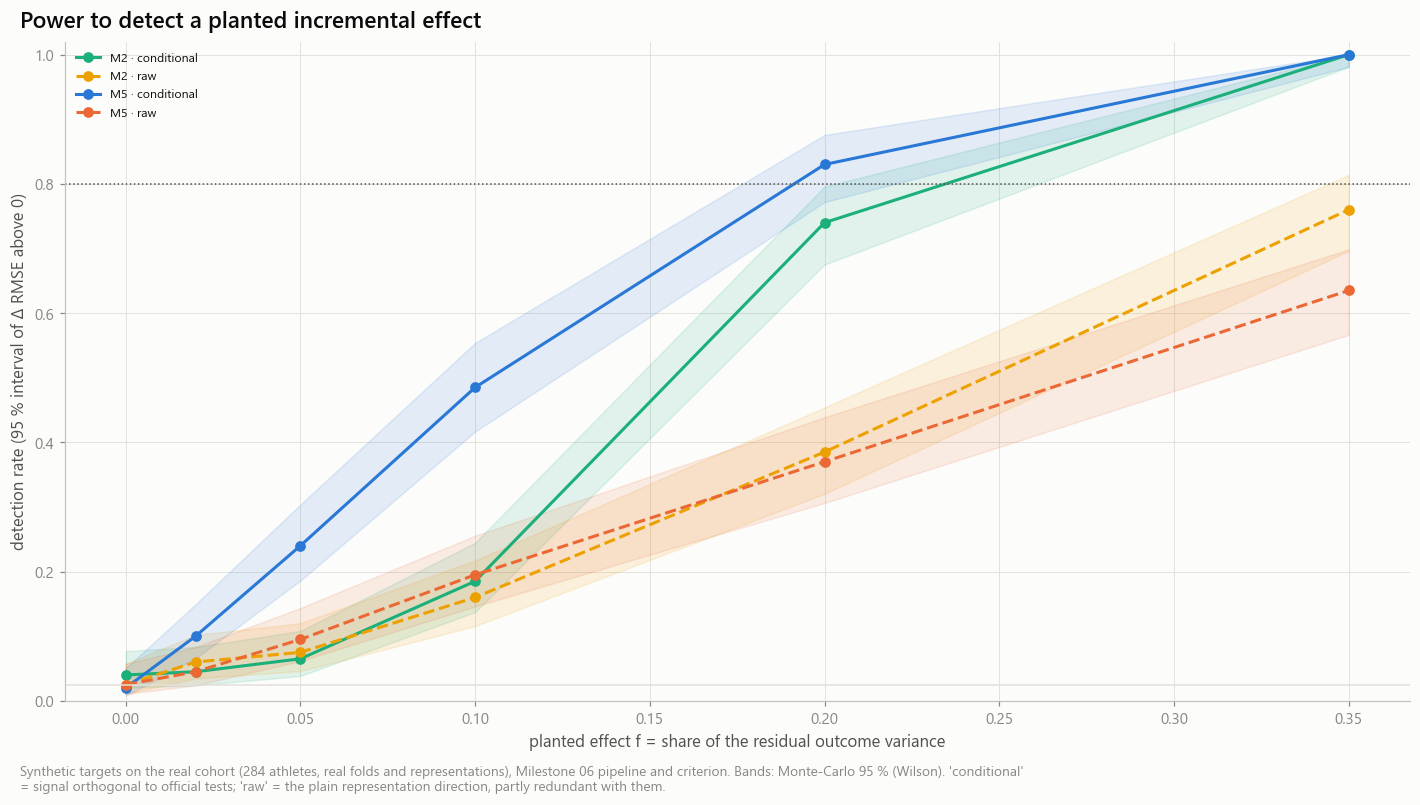

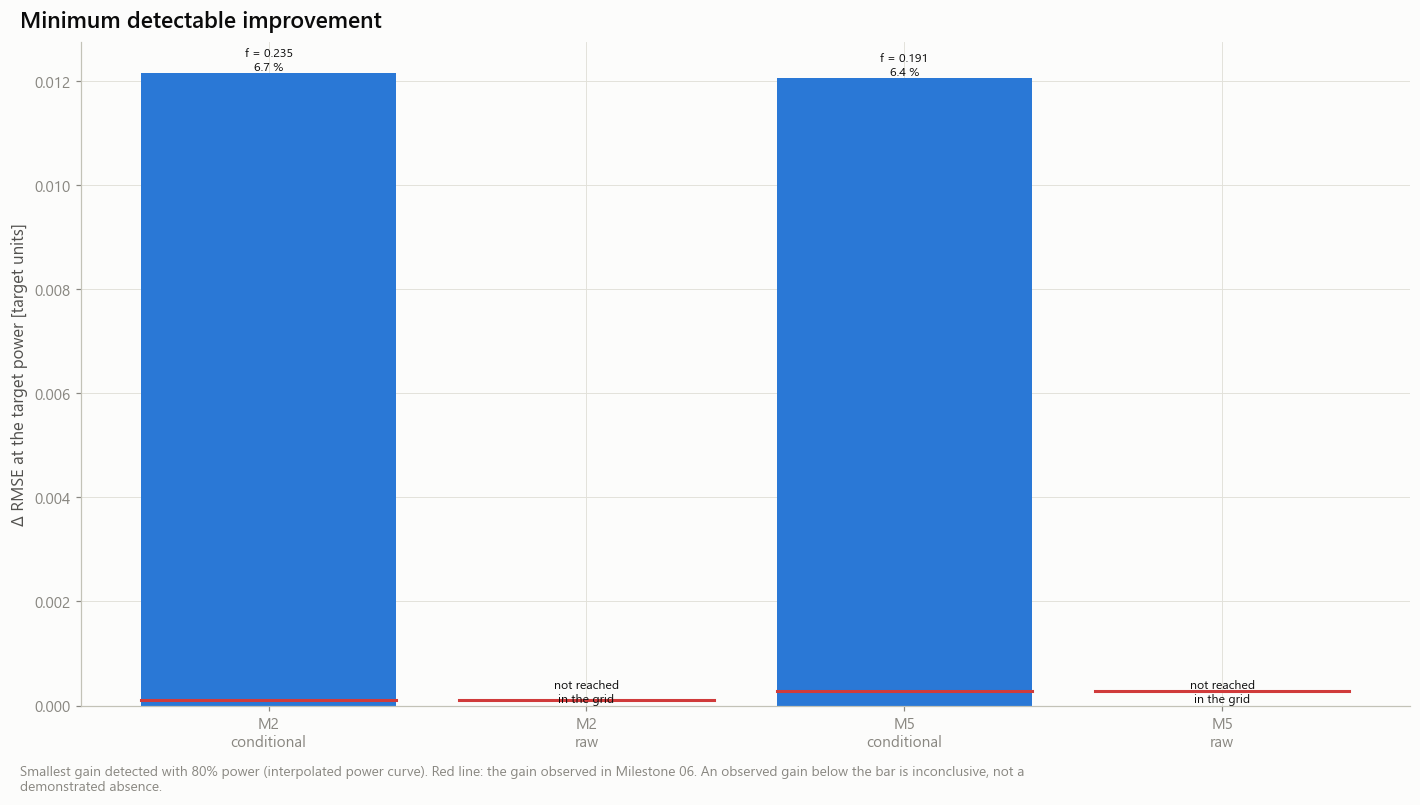

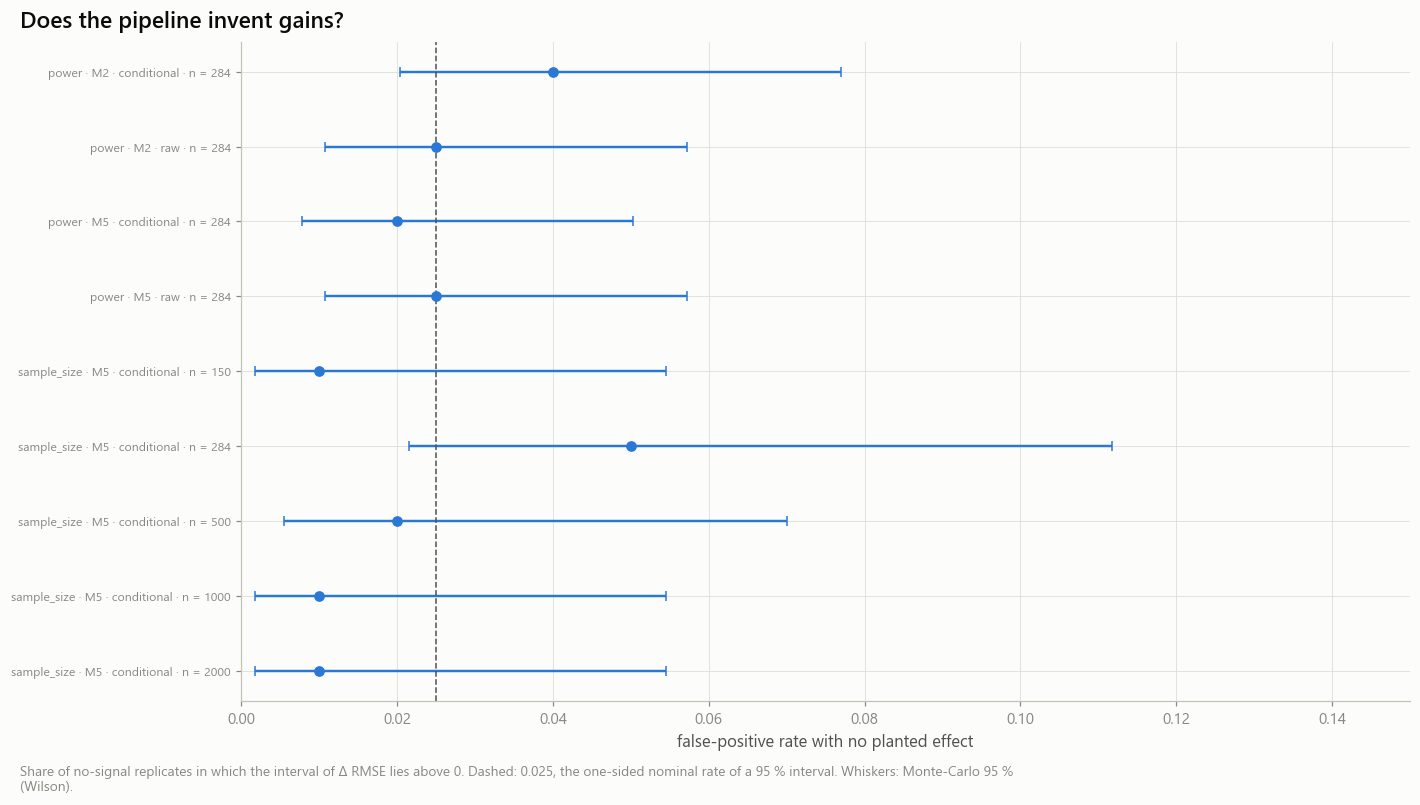

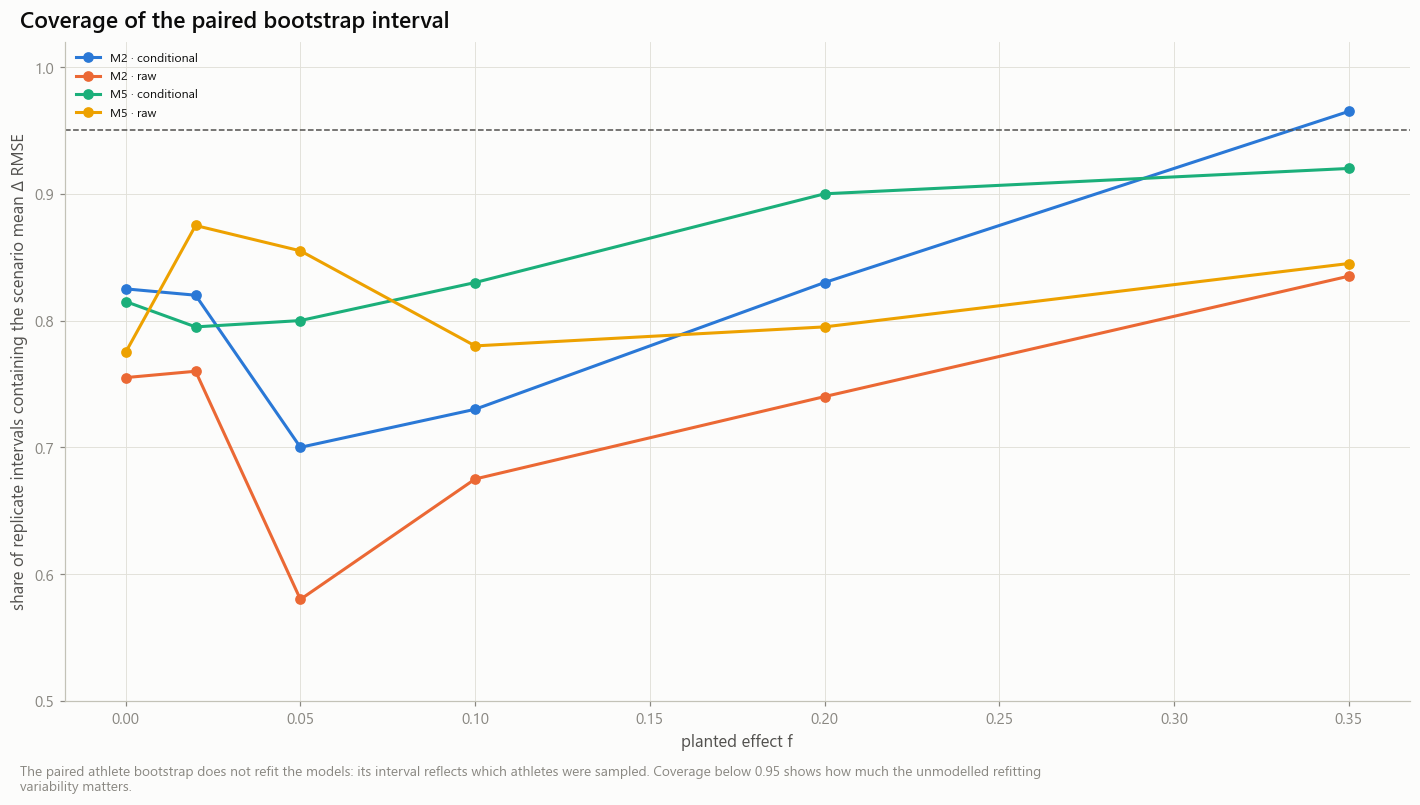

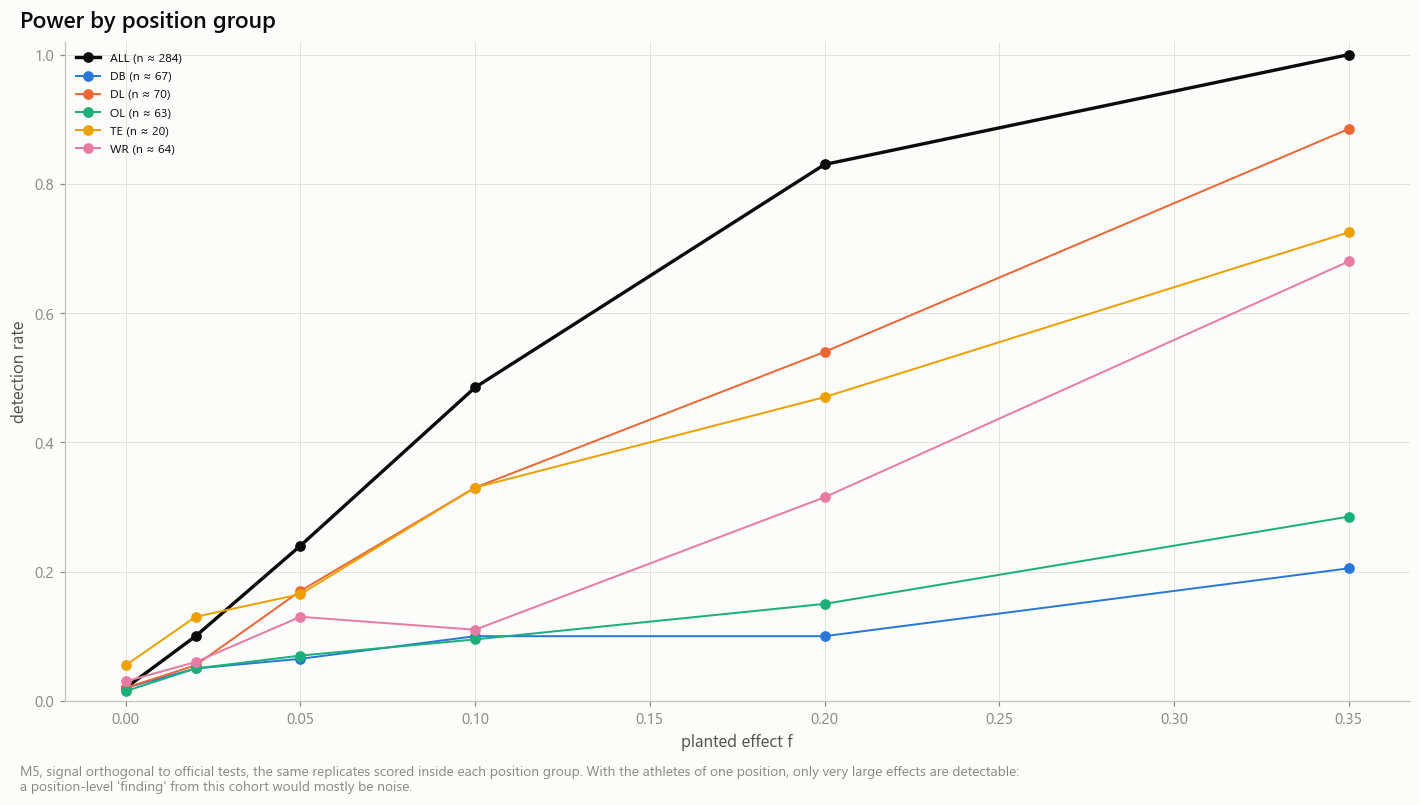

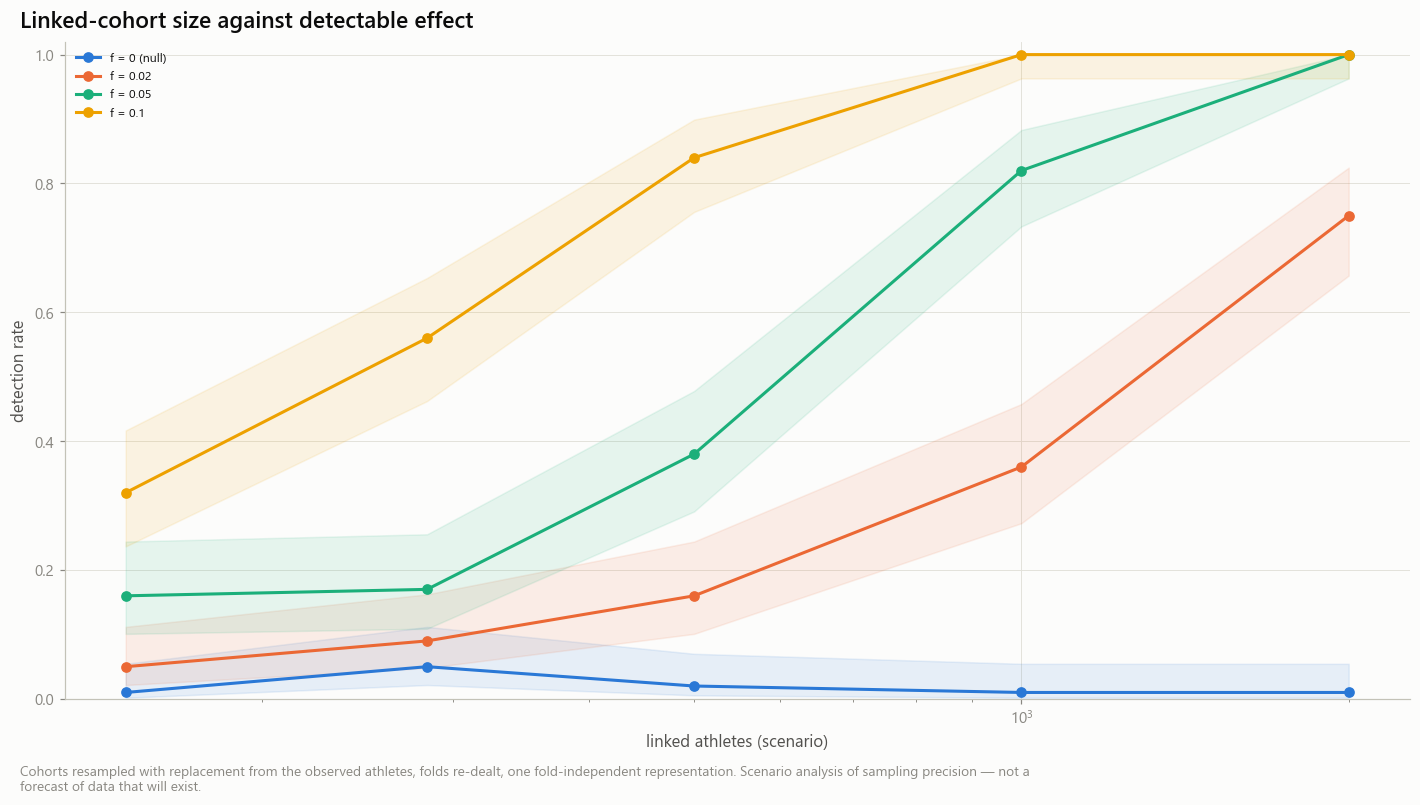

In [6]:
tp.assert_complete(summary)                                   # an incomplete simulation is never summarised
scen = tp.scenario_table(reps, plan)
null = tp.null_table(reps)
mde = tp.mde_table(scen, pc)
PROV = {'notebook': '07c_detectability_and_information_ceiling.ipynb', 'config_hash': summary['config_hash'], 'experiment_version': EXPERIMENT_VERSION,
        'power': pc.params(), 'target': P}
if controls.save_tables:
    for df, c in ((reps, tp.REPLICATES), (scen, tp.SCENARIOS), (null, tp.NULL), (mde, tp.MDE)):
        store.write(df, c, '07C', PROV)
ALLS = pl.col('scope') == 'ALL'
with pl.Config(tbl_rows=-1, tbl_cols=-1, float_precision=4):
    display(Markdown('**Power on the real cohort**'))
    display(scen.filter(ALLS & (pl.col('study') == 'power')).select('candidate', 'mode', 'effect', 'n_replicates', 'power', 'power_lower', 'power_upper',
                                                                    'mean_delta_rmse', 'mean_relative', 'mean_delta_r2', 'ci_coverage', 'complete'))
    display(Markdown('**No-signal calibration**'))
    display(null.filter(ALLS))
    display(Markdown('**Minimum detectable effects**'))
    display(mde.filter(ALLS))

def observed(c):
    r = m06_paired.filter((pl.col('analysis') == 'primary') & (pl.col('cohort') == 'primary') & (pl.col('target_id') == P) & (pl.col('metric') == 'delta_rmse')
                          & (pl.col('model') == c) & (pl.col('reference') == pc.reference))
    return {'estimate': r['estimate'][0], 'ci_lower': r['ci_lower'][0], 'ci_upper': r['ci_upper'][0]} if r.height else {'estimate': None, 'ci_lower': None, 'ci_upper': None}

OBSERVED = {c: observed(c) for c in pc.candidates}
N_NOTE = f'{design.n} athletes · {summary["planned_replicates"]} synthetic replicates'
store.show(cf.plot_power_curve(scen, pc.target_power), 'AM07C_01_power_vs_effect', {'scenarios': scen.filter(ALLS)}, publication=True, source='transfer_power_scenarios', n=N_NOTE)
store.show(cf.plot_mde(mde, {c: v['estimate'] for c, v in OBSERVED.items()}), 'AM07C_02_minimum_detectable_delta_rmse', {'mde': mde}, publication=True,
           source='transfer_mde_estimates', n=N_NOTE)
store.show(cf.plot_null(null), 'AM07C_03_false_positive_rate', {'null': null}, source='transfer_null_calibration', n=N_NOTE)
store.show(cf.plot_coverage(scen), 'AM07C_04_interval_coverage', {'scenarios': scen.filter(ALLS)}, source='transfer_power_scenarios', n=N_NOTE)
store.show(cf.plot_power_by_position(scen, pc.candidates[0]), 'AM07C_05_power_by_position', {'scenarios': scen.filter(pl.col('study') == 'power')},
           source='transfer_power_scenarios', n=N_NOTE)
store.show(cf.plot_sample_size(scen), 'AM07C_07_sample_size_vs_detectable', {'scenarios': scen.filter(pl.col('study') == 'sample_size')}, publication=True,
           source='transfer_power_scenarios', n='resampled cohorts (scenario analysis)')

## 4. Measurement attenuation, redundancy and information limits

**Attenuation.** With independent, non-differential error, an observed correlation is about `r_true · √(rel_x · rel_y)`. The reliabilities measured in this project are marked on the figure. This is the classical errors-in-variables approximation for a *correlation* — it is **not** a ceiling on predictive performance: a model is scored against the observed outcome, it can pool several noisy measurements, and context variance that is stable across games is "reliable" without being athletic. An ICC is not an information-theoretic bound.

**Redundancy.** A representation can be repeatable and still add little: the official design already explains a share of it, and only the remainder can be incremental. The redundancy table gives that share for every representation; the raw-versus-conditional power curves show its cost.

family,component,r2_position,r2_official,unique_share,n_athletes,n_official_terms
str,str,f64,f64,f64,i64,i64
"""ENG""","""direction_1""",0.621,0.892,0.108,284,17
"""ENG""","""dim_1""",0.621,0.892,0.108,284,17
"""SPEED2""","""direction_1""",0.727,0.971,0.029,284,17
"""SPEED2""","""dim_1""",0.727,0.971,0.029,284,17
"""SPEED2""","""dim_2""",0.727,0.971,0.029,284,17
"""FPCA""","""direction_1""",0.422,0.633,0.367,284,17
"""FPCA""","""dim_1""",0.742,0.980,0.020,284,17
"""FPCA""","""dim_2""",0.007,0.174,0.826,284,17
"""TCN""","""direction_1""",0.790,0.946,0.054,284,17


measure,reliability
str,f64
"""combine: speed development 4 →…",0.82411
"""combine: tracked top speed p95…",0.948451
"""nfl: O2.accel_sust05_mean (gam…",0.931649
"""nfl: context-conditioned C4 (c…",0.82928


16:00:52 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:07C] transfer_information_limits: 34 rows → warehouse/gold/advanced_movement/context_transfer/transfer_information_limits.parquet


topic,item,value,lower,upper,unit,note
str,str,f64,f64,f64,str,str
"""cohort""","""athletes""",284.0000,null,null,"""athletes""","""paired cohort of Milestone 06"""
"""cohort""","""rmse_official_model""",0.1794,null,null,"""target units""","""real M1 out-of-fold RMSE: the residual a candidate can still explain"""
"""redundancy""","""M5: R² of the planted direction on the official design""",0.9461,null,null,"""share""","""share of the representation's leading direction already explained by official testing"""
"""null""","""M5: false-positive rate""",0.0200,0.0078,0.0503,"""rate""","""nominal 0.025 (one-sided)"""
"""null""","""M5: SD of Δ RMSE with no signal""",0.0010,null,null,"""target units""","""sampling noise of the paired gain"""
"""null""","""M5: mean Δ RMSE with no signal""",-0.0003,null,null,"""target units""","""cost of fitting useless predictors"""
"""mde""","""M5 (conditional): effect f at 80% power""",0.1913,null,null,"""share of residual variance""",""""""
"""mde""","""M5 (conditional): Δ RMSE at 80% power""",0.0121,null,null,"""target units""",""""""
"""mde""","""M5 (conditional): relative Δ RMSE at 80% power""",0.0643,null,null,"""share of M1 RMSE""",""""""


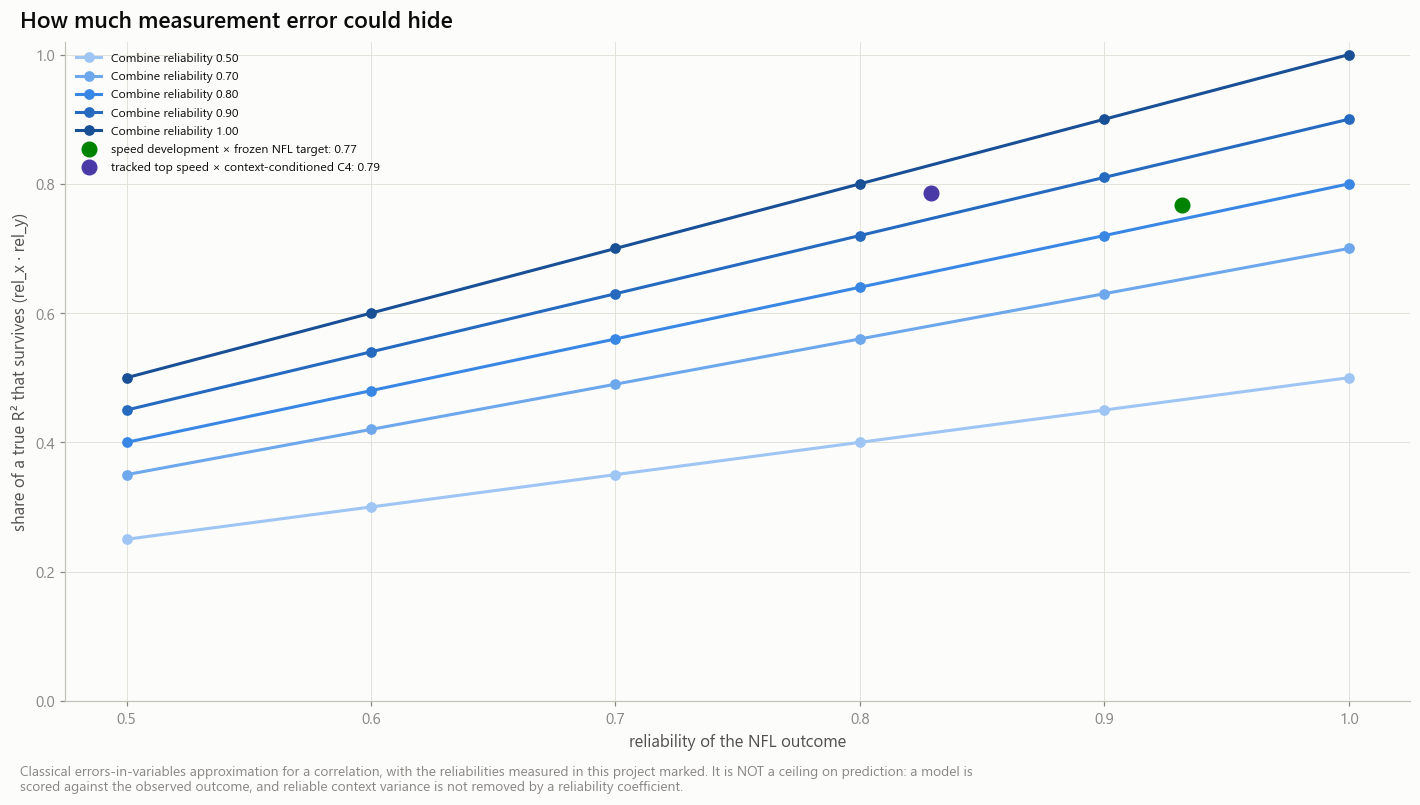

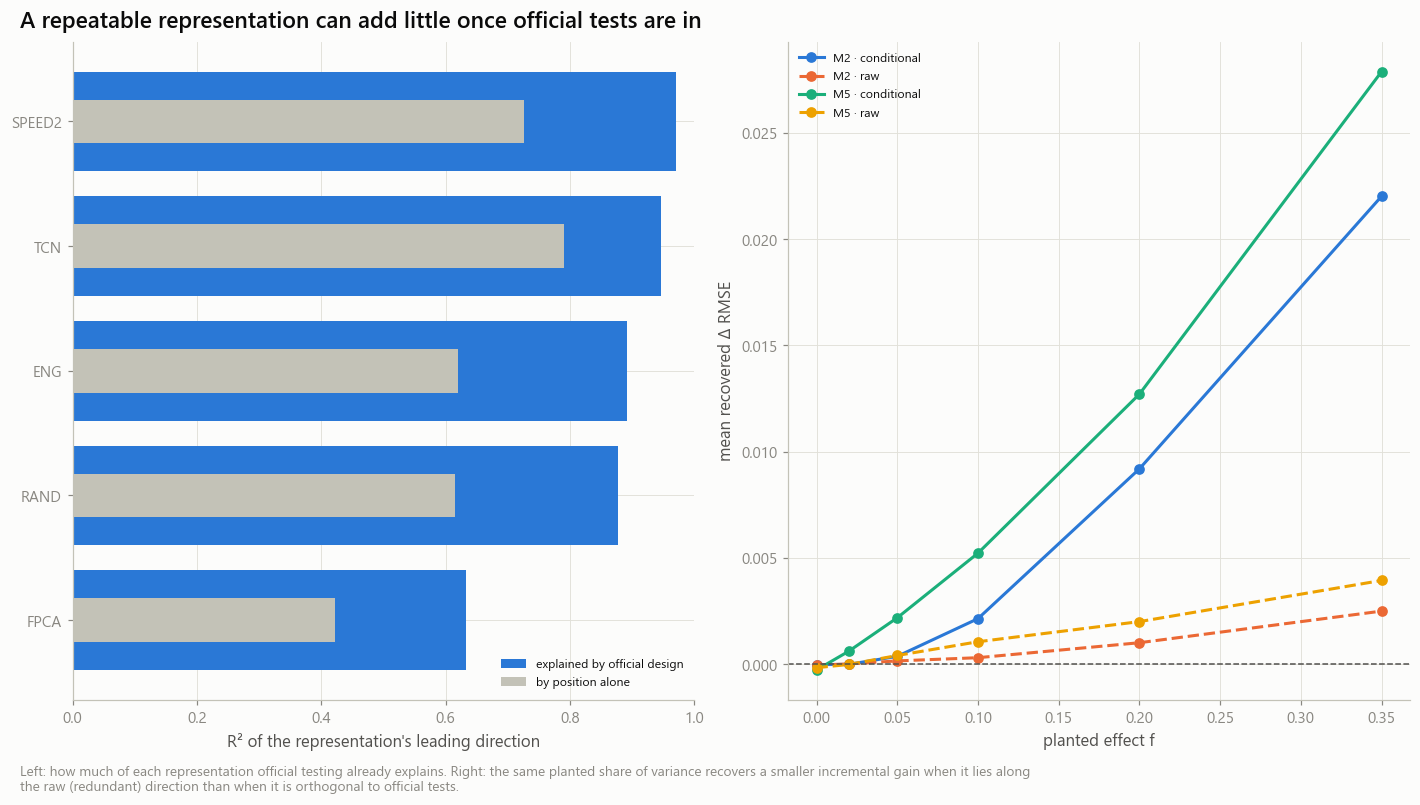

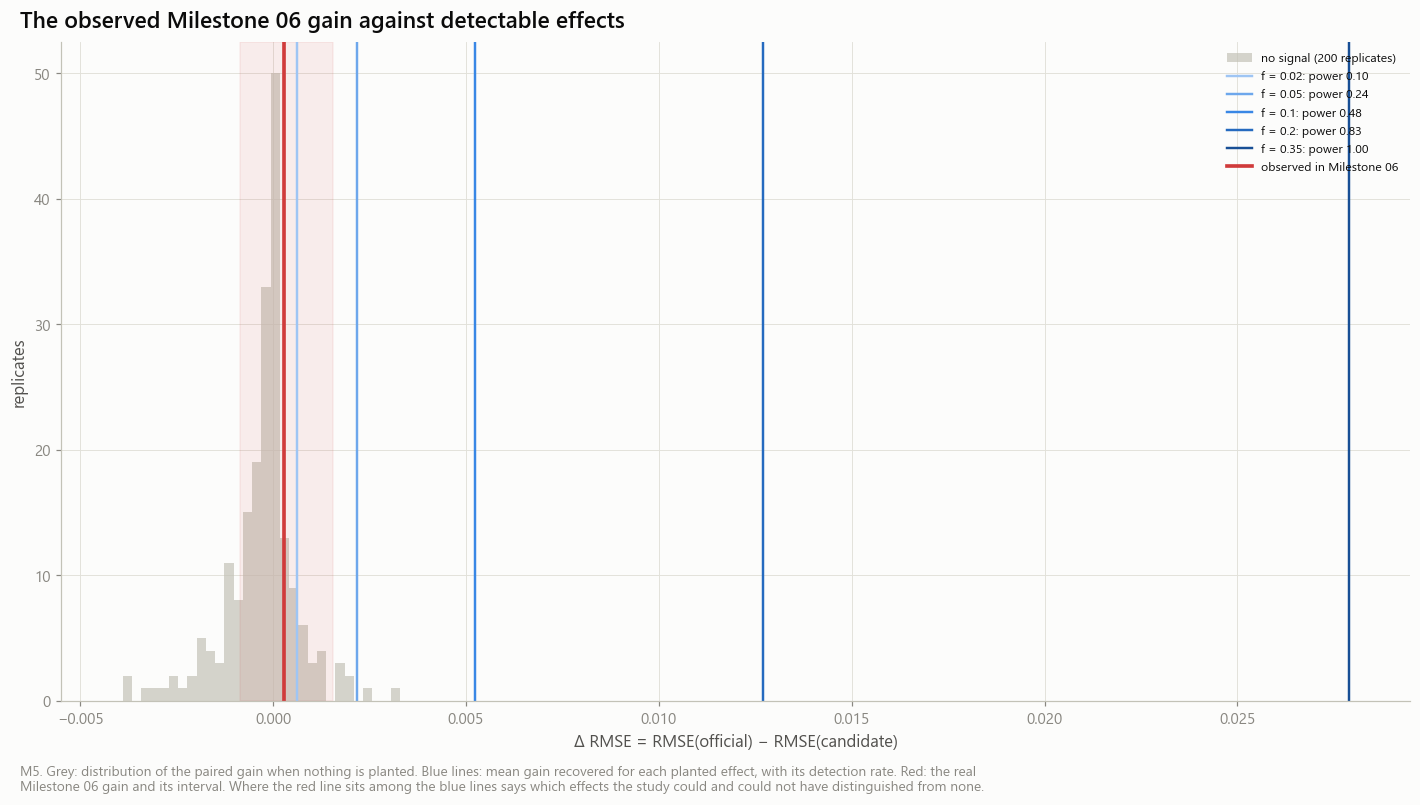

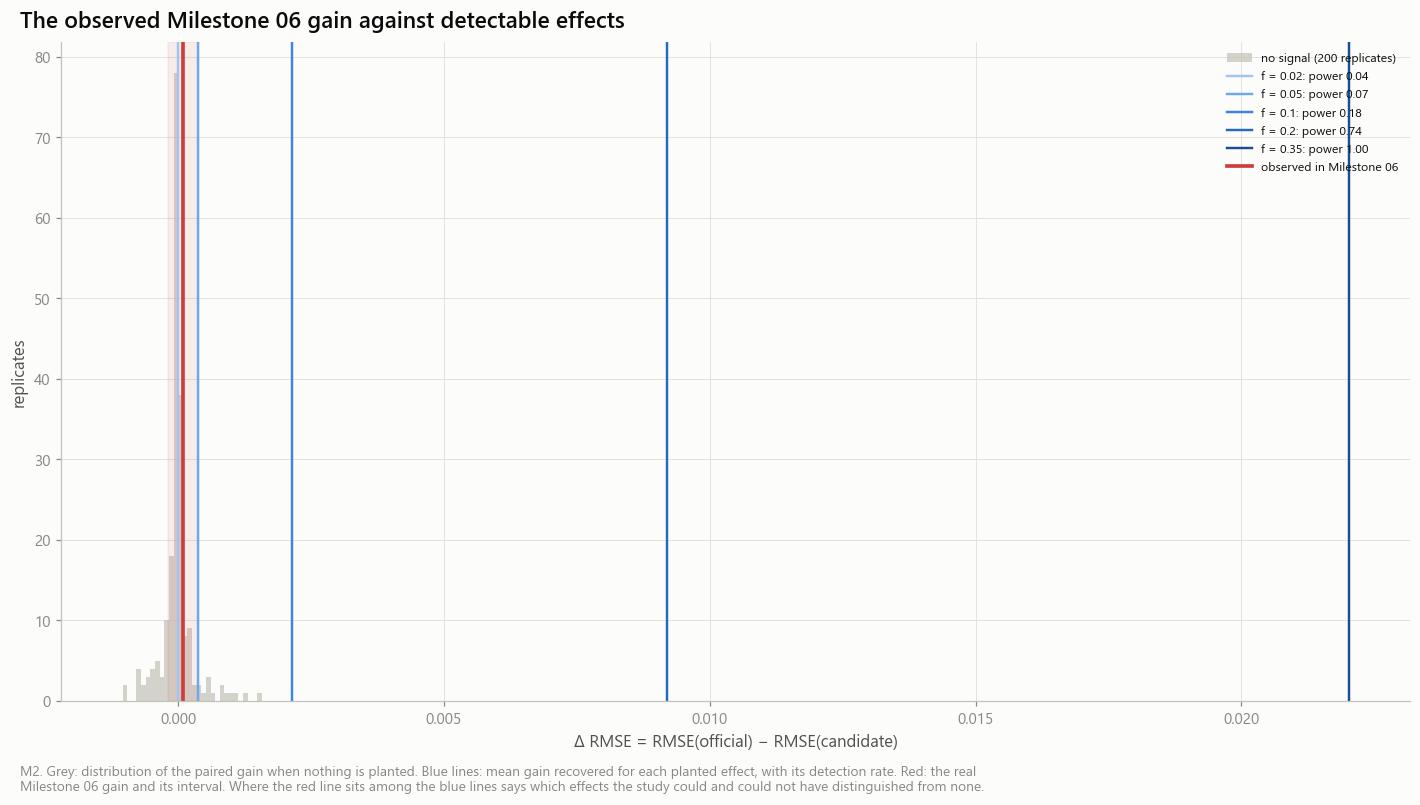

In [7]:
FAMILIES = [f for f in ('ENG', 'SPEED2', 'FPCA', 'TCN', 'RAND') if f in blocks.families()]
redundancy = tp.redundancy_table(design, blocks, tc, FAMILIES, pc.signal_fold)
with pl.Config(tbl_rows=-1, float_precision=3):
    display(redundancy)

# ---- reliabilities read from persisted tables (None when a table is absent: nothing is assumed)
status = store.atlas.require(at.STATUS, NB['04A'])
rel_of = lambda fid: (status.filter(pl.col('feature_id') == fid)['reliability'].to_list() or [None])[0]
frozen = {t['outcome_id']: (t.get('reliability') or {}).get('estimate') for t in registry_doc['targets']}
ctx_rel = None
if store.exists(cr.RELIABILITY):
    r = store.read(cr.RELIABILITY).filter((pl.col('definition') == 'C4') & (pl.col('method') == 'random_game_halves_crossfit') & (pl.col('scope') == 'ALL'))
    ctx_rel = r['reliability'][0] if r.height else None
RELIABILITIES = {'combine: speed development 4 → 8 yd/s (attempt ICC, 04A)': rel_of('F6.forty.time_v4_to_v8_s'),
                 'combine: tracked top speed p95 (attempt ICC, 04A)': rel_of('F2.forty.p95_speed'),
                 f'nfl: {P} (game halves, 05B)': frozen.get(P), 'nfl: context-conditioned C4 (cross-fitted game halves, 07A)': ctx_rel}
display(pl.DataFrame({'measure': list(RELIABILITIES), 'reliability': list(RELIABILITIES.values())}, schema={'measure': pl.String, 'reliability': pl.Float64}))

limits = tp.limits_table(scen, null, mde, st, OBSERVED, RELIABILITIES, pc)
grid = tp.attenuation_grid([0.3], [0.5, 0.7, 0.8, 0.9, 1.0], [0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
if controls.save_tables:
    store.write(limits, tp.LIMITS, '07C', PROV)
with pl.Config(tbl_rows=-1, float_precision=4, fmt_str_lengths=160):
    display(limits)

marks = {}
if RELIABILITIES['combine: speed development 4 → 8 yd/s (attempt ICC, 04A)'] is not None and frozen.get(P) is not None:
    marks['speed development × frozen NFL target'] = (RELIABILITIES['combine: speed development 4 → 8 yd/s (attempt ICC, 04A)'], frozen[P])
if RELIABILITIES['combine: tracked top speed p95 (attempt ICC, 04A)'] is not None and ctx_rel is not None:
    marks['tracked top speed × context-conditioned C4'] = (RELIABILITIES['combine: tracked top speed p95 (attempt ICC, 04A)'], ctx_rel)
store.show(cf.plot_attenuation(grid, marks), 'AM07C_06_reliability_attenuation', {'grid': grid}, source='attenuation approximation + persisted reliabilities', n='analytic')
store.show(cf.plot_redundancy(redundancy, scen), 'AM07C_08_collinearity_vs_incremental_signal', {'redundancy': redundancy}, publication=True,
           source='transfer_power_scenarios + representation blocks (06B)', n=N_NOTE)
for c in pc.candidates:
    ob = OBSERVED[c]
    store.show(cf.plot_observed_vs_detectable(reps, scen, c, ob['estimate'], ob['ci_lower'], ob['ci_upper']), f'AM07C_09_observed_vs_detectable_{c}',
               {'scenarios': scen.filter(ALLS & (pl.col('candidate') == c))}, publication=(c == pc.candidates[0]), source='transfer_planted_signal_recovery + transfer_paired_comparisons (06B)', n=N_NOTE)

## 5. Gate 07C and report

Gate 07C passes when the simulation is complete, its assumptions are stated, planted effects are recovered as planted, the null false-positive rate and the interval coverage are evaluated, and minimum detectable effects are quantified. It says nothing about the size of the real effect.

**Reading rule.** If the gain observed in Milestone 06 is smaller than the minimum detectable gain, the Milestone 06 result is *inconclusive about effects of that size* — not evidence that no relationship exists, and not evidence that one does.

In [8]:
gate = tp.gate_07c(summary, scen, null, mde, pc, tp.ASSUMPTIONS)
with pl.Config(tbl_rows=-1, fmt_str_lengths=400):
    display(gate)
GATE_07C = 'PASS' if gate['passed'].all() else 'FAIL'
text = tp.report_markdown(scen, null, mde, limits, summary, pc)
display(Markdown(text))
display(Markdown(f'**Gate 07C: {GATE_07C}**'))
if controls.save_tables:
    store.tables_dir.mkdir(parents=True, exist_ok=True)
    (store.tables_dir / 'transfer_power_report.md').write_text(text, encoding='utf-8')
    store.write_json('transfer_power_manifest', {
        'notebook': '07c_detectability_and_information_ceiling.ipynb', 'status': 'executed', 'experiment_version': EXPERIMENT_VERSION, 'seed': controls.seed,
        'simulation': summary, 'power_config': pc.params(), 'target': P, 'n_athletes': design.n, 'folds_hash': audit['folds_hash'],
        'targets_version_hash': registry_doc['version_hash'], 'observed_m06': OBSERVED, 'redundancy_r2_official': st.redundancy,
        'mde': mde.filter(ALLS & (pl.col('study') == 'power')).select('candidate', 'mode', 'mde_effect', 'mde_delta_rmse', 'mde_relative', 'max_power_reached').to_dicts(),
        'validation': dict(zip(validation['check'], validation['status'])), 'gate_07c': GATE_07C})
cr.assert_gate(gate, '07C')

criterion,passed,detail
str,bool,str
"""assumptions_documented""",true,"""synthetic-target model, direction and noise are stated in the report"""
"""simulation_complete""",true,"""6800 planned, 0 missing"""
"""planted_effects_recovered""",true,"""mean recovered Δ RMSE rises from the null to the largest planted effect and is positive there"""
"""null_false_positive_rate_checked""",true,"""M2 conditional: 0.040 [0.020, 0.077]; M2 raw: 0.025 [0.011, 0.057]; M5 conditional: 0.020 [0.008, 0.050]; M5 raw: 0.025 [0.011, 0.057]"""
"""interval_coverage_evaluated""",true,"""coverage of the scenario mean between 0.7 and 0.965"""
"""minimum_detectable_effects_quantified""",true,"""11 scenario(s) reach 80% power inside the effect grid"""


# Detectability of incremental Combine → NFL prediction (Milestone 07C)

Simulation `f7d3e88b6cd36566` — COMPLETE (6800 replicates).

## Assumptions

Synthetic target y* = μ + σ_res,pos · (√(1 − f) · ε + √f · z). μ = the athlete's real Milestone 06 out-of-fold prediction of the official model; σ_res,pos = SD of the real residuals of the position; ε = real standardised residuals resampled within position; z = unit-variance leading direction of the candidate representation (fold-0 encoder), either orthogonal to the official design ('conditional': f is the partial R² given official testing) or as is ('raw'). Folds, athletes, covariates, missingness and fold-fitted representations are the real ones; the pipeline, bootstrap and detection criterion are those of Milestone 06. The signal is linear and one-dimensional — favourable to a ridge read-out: real effects that are non-linear, spread over many weak directions or specific to a position are harder to detect than the planted ones, so the power shown is an upper reading.

## Power on the real cohort

| Candidate | Mode | f | Power [MC 95 %] | Mean Δ RMSE | Relative | Interval coverage |
|---|---|---|---|---|---|---|
| M2 | conditional | 0 | 0.040 [0.020, 0.077] | -0.0000 | -0.01 % | 0.825 |
| M2 | conditional | 0.02 | 0.045 [0.024, 0.083] | -0.0000 | -0.00 % | 0.820 |
| M2 | conditional | 0.05 | 0.065 [0.038, 0.108] | 0.0004 | 0.20 % | 0.700 |
| M2 | conditional | 0.1 | 0.185 [0.137, 0.245] | 0.0021 | 1.18 % | 0.730 |
| M2 | conditional | 0.2 | 0.740 [0.675, 0.796] | 0.0092 | 5.05 % | 0.830 |
| M2 | conditional | 0.35 | 1.000 [0.981, 1.000] | 0.0220 | 12.35 % | 0.965 |
| M2 | raw | 0 | 0.025 [0.011, 0.057] | -0.0000 | -0.02 % | 0.755 |
| M2 | raw | 0.02 | 0.060 [0.035, 0.102] | 0.0000 | 0.01 % | 0.760 |
| M2 | raw | 0.05 | 0.075 [0.046, 0.120] | 0.0002 | 0.09 % | 0.580 |
| M2 | raw | 0.1 | 0.160 [0.116, 0.217] | 0.0003 | 0.17 % | 0.675 |
| M2 | raw | 0.2 | 0.385 [0.320, 0.454] | 0.0010 | 0.60 % | 0.740 |
| M2 | raw | 0.35 | 0.760 [0.696, 0.814] | 0.0025 | 1.62 % | 0.835 |
| M5 | conditional | 0 | 0.020 [0.008, 0.050] | -0.0003 | -0.15 % | 0.815 |
| M5 | conditional | 0.02 | 0.100 [0.066, 0.149] | 0.0006 | 0.33 % | 0.795 |
| M5 | conditional | 0.05 | 0.240 [0.186, 0.304] | 0.0022 | 1.16 % | 0.800 |
| M5 | conditional | 0.1 | 0.485 [0.417, 0.554] | 0.0052 | 2.77 % | 0.830 |
| M5 | conditional | 0.2 | 0.830 [0.772, 0.876] | 0.0127 | 6.78 % | 0.900 |
| M5 | conditional | 0.35 | 1.000 [0.981, 1.000] | 0.0279 | 14.78 % | 0.920 |
| M5 | raw | 0 | 0.025 [0.011, 0.057] | -0.0002 | -0.09 % | 0.775 |
| M5 | raw | 0.02 | 0.045 [0.024, 0.083] | -0.0000 | -0.00 % | 0.875 |
| M5 | raw | 0.05 | 0.095 [0.062, 0.144] | 0.0004 | 0.23 % | 0.855 |
| M5 | raw | 0.1 | 0.195 [0.146, 0.255] | 0.0011 | 0.59 % | 0.780 |
| M5 | raw | 0.2 | 0.370 [0.306, 0.439] | 0.0020 | 1.16 % | 0.795 |
| M5 | raw | 0.35 | 0.635 [0.566, 0.699] | 0.0039 | 2.54 % | 0.845 |

## No-signal calibration

- power · M2 · conditional · n = 284 · ALL: false-positive rate 0.040 [0.020, 0.077] (nominal 0.025); mean Δ RMSE -0.00002, SD 0.00032
- power · M2 · raw · n = 284 · ALL: false-positive rate 0.025 [0.011, 0.057] (nominal 0.025); mean Δ RMSE -0.00004, SD 0.00038
- power · M5 · conditional · n = 284 · ALL: false-positive rate 0.020 [0.008, 0.050] (nominal 0.025); mean Δ RMSE -0.00027, SD 0.00096
- power · M5 · raw · n = 284 · ALL: false-positive rate 0.025 [0.011, 0.057] (nominal 0.025); mean Δ RMSE -0.00016, SD 0.00084
- sample_size · M5 · conditional · n = 150 · ALL: false-positive rate 0.010 [0.002, 0.054] (nominal 0.025); mean Δ RMSE -0.00031, SD 0.00206
- sample_size · M5 · conditional · n = 284 · ALL: false-positive rate 0.050 [0.022, 0.112] (nominal 0.025); mean Δ RMSE -0.00002, SD 0.00085
- sample_size · M5 · conditional · n = 500 · ALL: false-positive rate 0.020 [0.006, 0.070] (nominal 0.025); mean Δ RMSE -0.00010, SD 0.00053
- sample_size · M5 · conditional · n = 1000 · ALL: false-positive rate 0.010 [0.002, 0.054] (nominal 0.025); mean Δ RMSE -0.00014, SD 0.00040
- sample_size · M5 · conditional · n = 2000 · ALL: false-positive rate 0.010 [0.002, 0.054] (nominal 0.025); mean Δ RMSE -0.00006, SD 0.00016

## Minimum detectable effects

- power · M2 · conditional · n = 284 · ALL: f = 0.235, Δ RMSE 0.0122 (6.73 % of the official error)
- power · M2 · conditional · n = 284 · DB: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M2 · conditional · n = 284 · DL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M2 · conditional · n = 284 · OL: f = 0.343, Δ RMSE 0.0404 (26.52 % of the official error)
- power · M2 · conditional · n = 284 · TE: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M2 · conditional · n = 284 · WR: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M2 · raw · n = 284 · ALL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M2 · raw · n = 284 · DB: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M2 · raw · n = 284 · DL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M2 · raw · n = 284 · OL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M2 · raw · n = 284 · TE: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M2 · raw · n = 284 · WR: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M5 · conditional · n = 284 · ALL: f = 0.191, Δ RMSE 0.0121 (6.43 % of the official error)
- power · M5 · conditional · n = 284 · DB: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M5 · conditional · n = 284 · DL: f = 0.313, Δ RMSE 0.0335 (18.65 % of the official error)
- power · M5 · conditional · n = 284 · OL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M5 · conditional · n = 284 · TE: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M5 · conditional · n = 284 · WR: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M5 · raw · n = 284 · ALL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M5 · raw · n = 284 · DB: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M5 · raw · n = 284 · DL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M5 · raw · n = 284 · OL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M5 · raw · n = 284 · TE: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- power · M5 · raw · n = 284 · WR: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.35: the effect grid does not reach it
- sample_size · M5 · conditional · n = 150 · ALL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 150 · DB: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 150 · DL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 150 · OL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 150 · TE: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 150 · WR: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 284 · ALL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 284 · DB: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 284 · DL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 284 · OL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 284 · TE: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 284 · WR: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 500 · ALL: f = 0.096, Δ RMSE 0.0064 (3.50 % of the official error)
- sample_size · M5 · conditional · n = 500 · DB: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 500 · DL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 500 · OL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 500 · TE: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 500 · WR: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 1000 · ALL: f = 0.049, Δ RMSE 0.0033 (1.79 % of the official error)
- sample_size · M5 · conditional · n = 1000 · DB: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 1000 · DL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 1000 · OL: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 1000 · TE: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 1000 · WR: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 2000 · ALL: f = 0.026, Δ RMSE 0.0018 (1.00 % of the official error)
- sample_size · M5 · conditional · n = 2000 · DB: f = n/a, Δ RMSE n/a (n/a % of the official error) — power stays below 80% up to f = 0.1: the effect grid does not reach it
- sample_size · M5 · conditional · n = 2000 · DL: f = 0.047, Δ RMSE 0.0053 (3.28 % of the official error)
- sample_size · M5 · conditional · n = 2000 · OL: f = 0.088, Δ RMSE 0.0062 (5.08 % of the official error)
- sample_size · M5 · conditional · n = 2000 · TE: f = 0.090, Δ RMSE 0.0159 (6.81 % of the official error)
- sample_size · M5 · conditional · n = 2000 · WR: f = 0.077, Δ RMSE 0.0057 (2.23 % of the official error)

## Information limits

- [cohort] athletes: 284.0000 athletes — paired cohort of Milestone 06
- [cohort] rmse_official_model: 0.1794 target units — real M1 out-of-fold RMSE: the residual a candidate can still explain
- [redundancy] M5: R² of the planted direction on the official design: 0.9461 share — share of the representation's leading direction already explained by official testing
- [null] M5: false-positive rate: 0.0200 [0.0078, 0.0503] rate — nominal 0.025 (one-sided)
- [null] M5: SD of Δ RMSE with no signal: 0.0010 target units — sampling noise of the paired gain
- [null] M5: mean Δ RMSE with no signal: -0.0003 target units — cost of fitting useless predictors
- [mde] M5 (conditional): effect f at 80% power: 0.1913 share of residual variance
- [mde] M5 (conditional): Δ RMSE at 80% power: 0.0121 target units
- [mde] M5 (conditional): relative Δ RMSE at 80% power: 0.0643 share of M1 RMSE
- [mde] M5 (raw): effect f at 80% power: n/a share of residual variance — power stays below 80% up to f = 0.35: the effect grid does not reach it
- [mde] M5 (raw): Δ RMSE at 80% power: n/a target units
- [mde] M5 (raw): relative Δ RMSE at 80% power: n/a share of M1 RMSE
- [observed_m06] M5: Δ RMSE: 0.0003 [-0.0008, 0.0015] target units — real Milestone 06 comparison (unchanged)
- [observed_m06] M5: Δ RMSE in null SDs: 0.5739 SD — distance of the observed gain from the simulated no-signal mean
- [redundancy] M2: R² of the planted direction on the official design: 0.8915 share — share of the representation's leading direction already explained by official testing
- [null] M2: false-positive rate: 0.0400 [0.0204, 0.0769] rate — nominal 0.025 (one-sided)
- [null] M2: SD of Δ RMSE with no signal: 0.0003 target units — sampling noise of the paired gain
- [null] M2: mean Δ RMSE with no signal: -0.0000 target units — cost of fitting useless predictors
- [mde] M2 (conditional): effect f at 80% power: 0.2346 share of residual variance
- [mde] M2 (conditional): Δ RMSE at 80% power: 0.0122 target units
- [mde] M2 (conditional): relative Δ RMSE at 80% power: 0.0673 share of M1 RMSE
- [mde] M2 (raw): effect f at 80% power: n/a share of residual variance — power stays below 80% up to f = 0.35: the effect grid does not reach it
- [mde] M2 (raw): Δ RMSE at 80% power: n/a target units
- [mde] M2 (raw): relative Δ RMSE at 80% power: n/a share of M1 RMSE
- [observed_m06] M2: Δ RMSE: 0.0001 [-0.0002, 0.0004] target units — real Milestone 06 comparison (unchanged)
- [observed_m06] M2: Δ RMSE in null SDs: 0.3605 SD — distance of the observed gain from the simulated no-signal mean
- [reliability] combine: speed development 4 → 8 yd/s (attempt ICC, 04A): 0.8241 reliability — read from persisted Milestone 04–07A tables
- [reliability] combine: tracked top speed p95 (attempt ICC, 04A): 0.9485 reliability — read from persisted Milestone 04–07A tables
- [reliability] nfl: O2.accel_sust05_mean (game halves, 05B): 0.9316 reliability — read from persisted Milestone 04–07A tables
- [reliability] nfl: context-conditioned C4 (cross-fitted game halves, 07A): 0.8293 reliability — read from persisted Milestone 04–07A tables
- [attenuation] combine: speed development 4 → 8 yd/s (attempt ICC, 04A) × nfl: O2.accel_sust05_mean (game halves, 05B): √(rel_x · rel_y): 0.8762 factor on a correlation — classical approximation, NOT a ceiling on prediction (see transfer_power.attenuation)
- [attenuation] combine: speed development 4 → 8 yd/s (attempt ICC, 04A) × nfl: context-conditioned C4 (cross-fitted game halves, 07A): √(rel_x · rel_y): 0.8267 factor on a correlation — classical approximation, NOT a ceiling on prediction (see transfer_power.attenuation)
- [attenuation] combine: tracked top speed p95 (attempt ICC, 04A) × nfl: O2.accel_sust05_mean (game halves, 05B): √(rel_x · rel_y): 0.9400 factor on a correlation — classical approximation, NOT a ceiling on prediction (see transfer_power.attenuation)
- [attenuation] combine: tracked top speed p95 (attempt ICC, 04A) × nfl: context-conditioned C4 (cross-fitted game halves, 07A): √(rel_x · rel_y): 0.8869 factor on a correlation — classical approximation, NOT a ceiling on prediction (see transfer_power.attenuation)

Reading rules: (1) an observed gain smaller than the minimum detectable gain is INCONCLUSIVE, not a demonstrated absence; (2) the attenuation factor is a classical approximation for a correlation and is not a ceiling on prediction; (3) sample-size rows resample the observed athletes — scenario analysis, not a claim about data that will exist; (4) position-level rows have few athletes and wide Monte-Carlo and sampling error.

**Gate 07C: PASS**

### What to send back

The validation table; the run summary line of section 2 (with the time estimate printed by the first replicate); the three tables of section 3; the redundancy and limits tables of section 4; the gate and the report (section 5); figures `AM07C_01`, `AM07C_02`, `AM07C_07`, `AM07C_08`, `AM07C_09_*`; any traceback.

**Next:** `07d_athletic_fingerprint_scorecard.ipynb` (same `RUN_MODE`).